# تمرین ۱ — طبقه‌بندی چندکلاسه Stack Overflow با شبکه بازگشتی GRU دوسویه (RNN)

**انجام‌دهنده: مسعود کارگر**  |  درس: یادگیری عمیق / پردازش زبان طبیعی

> حالت پیش‌فرض از داده‌های واقعی استفاده می‌کند. برای بررسی سریع بدون اینترنت فقط متغیر محیطی `NB_OFFLINE_SMOKE=1` را قبل از شروع نوت‌بوک تنظیم کنید. در این حالت، خروجی‌ها صرفاً آزمون عملکرد کد هستند و **معیار عملکرد روی دیتاست اصلی محسوب نمی‌شوند**.

منابع: [TensorFlow original exercise](https://www.tensorflow.org/tutorials/keras/text_classification), [دیتاست Stack Overflow](https://storage.googleapis.com/download.tensorflow.org/data/stack_overflow_16k.tar.gz). پیاده‌سازی معادل با PyTorch انجام شده است.

In [1]:
import os, random, re, time, io, tarfile, urllib.request
from collections import Counter
from pathlib import Path
import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(min(2,torch.get_num_threads()))
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SMOKE=os.getenv('NB_OFFLINE_SMOKE','0')=='1'
print('PyTorch:',torch.__version__,'| device:',DEVICE,'| mode:', 'OFFLINE SMOKE TEST' if SMOKE else 'REAL DATASET')

PyTorch: 2.15.0+cu132 | device: cpu | mode: REAL DATASET


In [2]:
LABELS=['csharp','java','javascript','python']; label_to_id={x:i for i,x in enumerate(LABELS)}
URL='https://storage.googleapis.com/download.tensorflow.org/data/stack_overflow_16k.tar.gz'

def load_questions():
    if SMOKE:
        templates={
        'python':['How to use True and False in a list comprehension?', 'Why does dict.get(key) return None?', 'Use def hello(): and print(1) in a function.', 'How can I iterate with for x in range(5):?'],
        'csharp':['Why does public class Foo { bool x = true; } fail?', 'How to use Console.WriteLine("hello");?', 'What does using System; mean in C#?', 'How can I create List<int> with new List<int>()?'],
        'java':['Why does public static void main(String[] args) { } fail?', 'How do I use System.out.println("hi");?', 'How to create ArrayList<String> in Java?', 'What does new HashMap<String,Integer>() do?'],
        'javascript':['How to use const x = () => true; ?', 'Why does console.log(undefined) show undefined?', 'How to select document.querySelector("div")?', 'What happens with let x = null; in JS?']}
        # Duplicate and shuffle only for functionality testing, not for evaluation claims.
        pairs=[(t,label_to_id[l]) for l,ts in templates.items() for t in ts for _ in range(5)]
        random.Random(SEED).shuffle(pairs)
        return pairs[:64],pairs[64:72],pairs[72:]
    dest=Path('data/stack_overflow_16k');dest.mkdir(parents=True,exist_ok=True)
    if not (dest/'train').exists():
        print('Downloading Stack Overflow 16k from TensorFlow ...')
        archive=Path('data/stack_overflow_16k.tar.gz')
        if not archive.exists(): urllib.request.urlretrieve(URL,archive)
        with tarfile.open(archive) as tar:
            for member in tar.getmembers():
                path=(dest/member.name).resolve()
                if not path.is_relative_to(dest.resolve()):raise ValueError('Unsafe archive entry')
            tar.extractall(dest,filter='data')
    def read_folder(split):
        pairs=[]
        for name in LABELS:
            for p in sorted((dest/split/name).glob('*.txt')):
                pairs.append((p.read_text(encoding='utf-8',errors='replace'),label_to_id[name]))
        return pairs
    train=read_folder('train');test=read_folder('test')
    if not train or not test:raise RuntimeError('Stack Overflow dataset could not be loaded')
    random.Random(SEED).shuffle(train)
    cut=int(len(train)*.10)
    return train[cut:],train[:cut],test
train_pairs,val_pairs,test_pairs=load_questions()
print('train/validation/test:',len(train_pairs),len(val_pairs),len(test_pairs))
print('classes:',LABELS)
# Important: case and punctuation are preserved. No lowercasing, no standardize.
TOKEN_RE=re.compile(r'[A-Za-z_][A-Za-z_0-9]*|\d+|[^\w\s]|[^\W\d_]+', re.UNICODE)
def tokenize(s):return TOKEN_RE.findall(s)
print('Tokenization check:', tokenize('True true: foo(x) { return x; }'))
assert 'True' in tokenize('True true') and 'true' in tokenize('True true')
assert '{' in tokenize('if(x){ y(); }')
cnt=Counter(token for text,_ in train_pairs for token in tokenize(text))
MAX_VOCAB=12000;MAX_LEN=180 if not SMOKE else 42
vocab={'<PAD>':0,'<UNK>':1}
for word,_ in cnt.most_common(MAX_VOCAB-2):vocab[word]=len(vocab)
def encode(text):return [vocab.get(w,1) for w in tokenize(text)[:MAX_LEN]] or [1]
class QuestionData(Dataset):
    def __init__(self,pairs):self.pairs=pairs
    def __len__(self):return len(self.pairs)
    def __getitem__(self,i):
        x,y=self.pairs[i];return torch.tensor(encode(x)),y

def collate(batch):
    xs,ys=zip(*batch)
    x=nn.utils.rnn.pad_sequence(xs,batch_first=True,padding_value=0)
    return x,torch.tensor(ys,dtype=torch.long)
BATCH=32 if not SMOKE else 16
train_dl=DataLoader(QuestionData(train_pairs),batch_size=BATCH,shuffle=True,collate_fn=collate)
val_dl=DataLoader(QuestionData(val_pairs),batch_size=BATCH,collate_fn=collate)
test_dl=DataLoader(QuestionData(test_pairs),batch_size=BATCH,collate_fn=collate)

train/validation/test: 7200 800 8000
classes: ['csharp', 'java', 'javascript', 'python']
Tokenization check: ['True', 'true', ':', 'foo', '(', 'x', ')', '{', 'return', 'x', ';', '}']


## معماری مدل

خروجی دقیقاً **۴ نورون** دارد. تابع خطا `CrossEntropyLoss` برای دسته‌بندی چندکلاسه استفاده می‌شود و هیچ استانداردسازی یا lowercase انجام نمی‌شود.

In [3]:
class BidirectionalGRU(nn.Module):
    def __init__(self,n_vocab,n_classes):
        super().__init__()
        self.embedding=nn.Embedding(n_vocab,64,padding_idx=0)
        self.gru=nn.GRU(64,64,num_layers=1,batch_first=True,bidirectional=True)
        self.fc=nn.Sequential(nn.Dropout(.2),nn.Linear(128,n_classes))
    def forward(self,x):
        lengths=x.ne(0).sum(1).cpu()
        packed=nn.utils.rnn.pack_padded_sequence(self.embedding(x),lengths,batch_first=True,enforce_sorted=False)
        _,h=self.gru(packed)
        last=torch.cat((h[-2],h[-1]),dim=-1)
        return self.fc(last)
model=BidirectionalGRU(len(vocab),len(LABELS))

In [4]:
print(model)
assert model.fc[-1].out_features==4

BidirectionalGRU(
  (embedding): Embedding(12000, 64, padding_idx=0)
  (gru): GRU(64, 64, batch_first=True, bidirectional=True)
  (fc): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=128, out_features=4, bias=True)
  )
)


In [5]:
# CrossEntropyLoss is the categorical (multi-class) counterpart of binary loss.
# It expects integer class labels and logits; one-hot encoding is unnecessary.
model=model.to(DEVICE)
loss_fn=nn.CrossEntropyLoss()
optimizer=torch.optim.AdamW(model.parameters(),lr=0.002)
def epoch_pass(loader,training=False):
    model.train(training);total=correct=count=0
    for x,y in loader:
        x,y=x.to(DEVICE),y.to(DEVICE)
        with torch.set_grad_enabled(training):
            logits=model(x);loss=loss_fn(logits,y)
            if training:
                optimizer.zero_grad();loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(),1.0)
                optimizer.step()
        bs=len(y);total+=loss.item()*bs
        correct+=(logits.argmax(-1)==y).sum().item();count+=bs
    return total/count,correct/count
EPOCHS=3 if SMOKE else 6
history=[]
for epoch in range(EPOCHS):
    tr=epoch_pass(train_dl,True);va=epoch_pass(val_dl)
    history.append((tr,va))
    print(f'epoch {epoch+1:02d}: train_loss={tr[0]:.4f}, train_acc={tr[1]:.3f} | val_loss={va[0]:.4f}, val_acc={va[1]:.3f}')
test_loss,test_acc=epoch_pass(test_dl)
print(f'TEST: loss={test_loss:.4f}, accuracy={test_acc:.3f}')
if SMOKE:print('NOTICE: metrics are from synthetic offline smoke data, NOT the real Stack Overflow dataset.')

epoch 01: train_loss=1.1998, train_acc=0.434 | val_loss=0.8964, val_acc=0.614


epoch 02: train_loss=0.7315, train_acc=0.691 | val_loss=0.6301, val_acc=0.751


epoch 03: train_loss=0.4913, train_acc=0.813 | val_loss=0.5063, val_acc=0.806


epoch 04: train_loss=0.3272, train_acc=0.882 | val_loss=0.4927, val_acc=0.819


epoch 05: train_loss=0.2234, train_acc=0.924 | val_loss=0.5565, val_acc=0.819


epoch 06: train_loss=0.1237, train_acc=0.957 | val_loss=0.6159, val_acc=0.818


TEST: loss=0.5878, accuracy=0.823


## ارزیابی روی مجموعه آزمون مستقل

In [6]:
from sklearn.metrics import classification_report,confusion_matrix
model.eval();yt=[];yp=[]
with torch.no_grad():
    for x,y in test_dl:
        prediction=model(x.to(DEVICE)).argmax(1).cpu().tolist()
        yt.extend(y.tolist());yp.extend(prediction)
print(classification_report(yt,yp,labels=list(range(4)),target_names=LABELS,zero_division=0))
print('confusion matrix (rows=true, columns=pred):\n',confusion_matrix(yt,yp,labels=list(range(4))))
examples=['How do I use True inside def foo(x): return x?','public class A { bool enabled = true; }', 'console.log(x) => undefined;','System.out.println("Hello");']
with torch.no_grad():
    x,_=collate([(torch.tensor(encode(t)),0) for t in examples]);pred=model(x.to(DEVICE)).softmax(-1).cpu()
for s,p in zip(examples,pred):print(f'{LABELS[int(p.argmax())]} ({p.max():.2f}) <- {s}')

              precision    recall  f1-score   support

      csharp       0.75      0.78      0.77      2000
        java       0.82      0.74      0.78      2000
  javascript       0.85      0.88      0.87      2000
      python       0.88      0.88      0.88      2000

    accuracy                           0.82      8000
   macro avg       0.82      0.82      0.82      8000
weighted avg       0.82      0.82      0.82      8000

confusion matrix (rows=true, columns=pred):
 [[1566  200  153   81]
 [ 319 1489   91  101]
 [ 114   53 1764   69]
 [  88   79   69 1764]]
python (0.99) <- How do I use True inside def foo(x): return x?
csharp (1.00) <- public class A { bool enabled = true; }
javascript (0.89) <- console.log(x) => undefined;
java (0.99) <- System.out.println("Hello");


**توضیح:** خروجی حالت smoke صرفاً برای تأیید اجرای سلول‌هاست؛ برای گزارش علمی باید روی حالت واقعی اجرا شود.

## نمودارهای آموزش و ارزیابی

در حالت اجرای اصلی، نمودارها از تاریخچهٔ آموزش روی مجموعه Stack Overflow و پیش‌بینی‌های مجموعهٔ آزمون مستقل رسم می‌شوند.

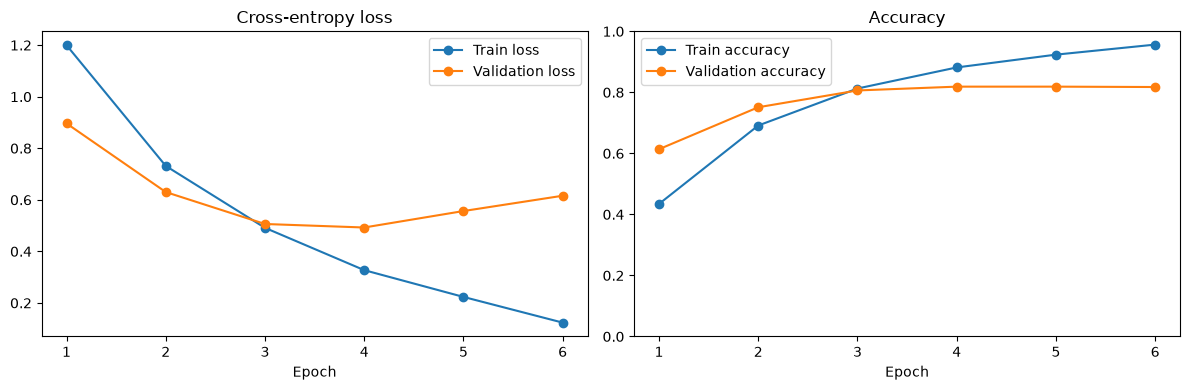

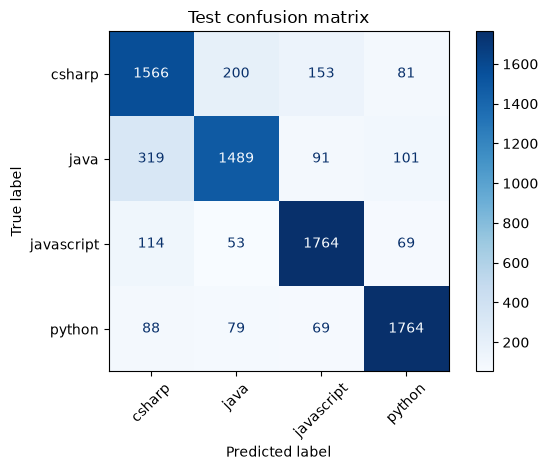

Final independent test accuracy: 0.8229


In [7]:
import matplotlib.pyplot as plt
epochs=range(1,len(history)+1)
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(epochs,[h[0][0] for h in history],marker='o',label='Train loss')
axes[0].plot(epochs,[h[1][0] for h in history],marker='o',label='Validation loss')
axes[0].set_title('Cross-entropy loss');axes[0].set_xlabel('Epoch');axes[0].legend()
axes[1].plot(epochs,[h[0][1] for h in history],marker='o',label='Train accuracy')
axes[1].plot(epochs,[h[1][1] for h in history],marker='o',label='Validation accuracy')
axes[1].set_title('Accuracy');axes[1].set_xlabel('Epoch');axes[1].set_ylim(0,1);axes[1].legend()
plt.tight_layout();plt.show()
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(yt,yp,display_labels=LABELS,cmap='Blues',xticks_rotation=45)
plt.title('Test confusion matrix');plt.tight_layout();plt.show()
print('Final independent test accuracy:',round(test_acc,4))
